# When AI Stocks Are the Market: Managing AI-Driven Concentration Risk and Hedging Its Tail

The ten largest US stocks — mostly AI leaders — now carry about 40% of the S&P 500's
weight. Prior research says concentration does not predict returns, so investors should
"do nothing". This notebook tests whether concentration still changes a portfolio's
**tail risk**, compares ways to manage the concentration, and asks which hedge protects
a concentrated portfolio best **after costs**.

**Author:** Kavin Dhanasekaran — MS Financial Engineering, NYU Tandon. Research only, not investment advice.

In [5]:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import config, data_loaders as dl

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
np.random.seed(config.RANDOM_SEED)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 1. Load and cache data

Download (or load from cache) every series the project needs and print each one's date
range as a sanity check. Raw files are cached under `data/raw/`, processed series under
`data/processed/`; nothing re-downloads unless `force=True`.

In [6]:
industries = dl.load_industry_portfolios()
ff_factors = dl.load_ff_factors()
candidate_prices = dl.load_prices(config.CANDIDATE_TICKERS, "candidates", start="2009-01-01")
index_prices = dl.load_prices(config.INDEX_TICKERS, "index", start="2009-01-01")
vix = dl.load_vix_term_structure()
pput = dl.load_pput()
rf_daily = dl.load_risk_free_daily()
shares = dl.load_shares_outstanding(config.CANDIDATE_TICKERS)

In [7]:
def _range_row(name, obj):
    idx = obj.index
    cols = obj.shape[1] if hasattr(obj, "shape") and obj.ndim == 2 else 1
    return {"series": name, "start": idx.min().date(), "end": idx.max().date(),
            "rows": len(idx), "cols": cols}

sanity = pd.DataFrame([
    _range_row("49 industry returns (monthly)", industries["returns"]),
    _range_row("Fama-French factors (monthly)", ff_factors),
    _range_row("candidate mega-cap prices (daily)", candidate_prices),
    _range_row("index & hedge prices (daily)", index_prices),
    _range_row("VIX term structure (daily)", vix),
    _range_row("PPUT benchmark (daily)", pput.to_frame()),
    _range_row("risk-free DTB3 (daily)", rf_daily.to_frame()),
    _range_row("shares outstanding (EDGAR)", shares),
])
sanity.set_index("series")

,start,end,rows,cols
series,,,,
49 industry returns (monthly),1926-07-31,2026-08-31,1202,49
Fama-French factors (monthly),1926-07-31,2026-08-31,1202,5
candidate mega-cap prices (daily),2009-01-02,2026-10-13,4472,32
index & hedge prices (daily),2009-01-02,2026-10-13,4472,4
VIX term structure (daily),1990-01-02,2026-10-13,9265,5
PPUT benchmark (daily),1986-06-30,2026-10-12,10144,1
risk-free DTB3 (daily),1954-01-04,2026-10-08,18184,1
shares outstanding (EDGAR),2009-01-31,2026-09-07,1095,32


## 2. Replication of Kritzman & Turkington (2025)

We rebuild a simplified market-concentration series — the effective number of
industries, `1 / Σ wᵢ²` on the 49 value-weighted industry caps — then test whether it
predicts future returns, volatility or drawdowns (Newey-West errors), and run their
concentration-timing rule against buy-and-hold.

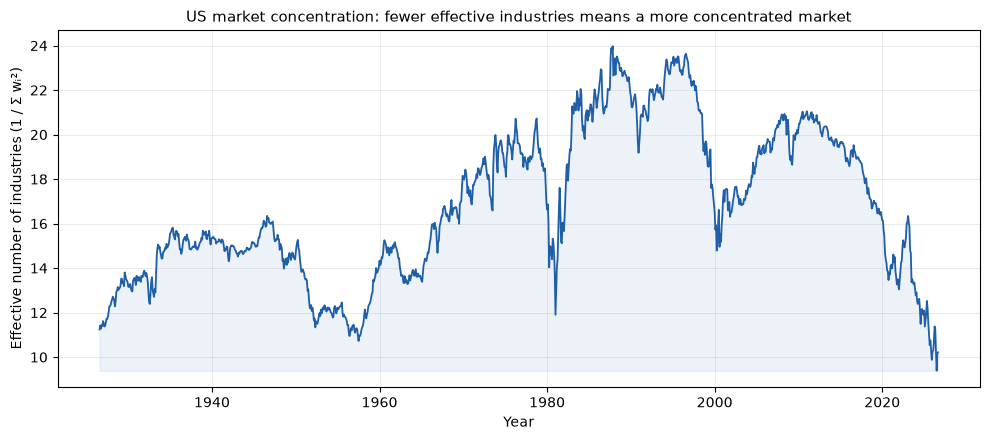

Effective industries: min 9.4, max 24.0, latest 10.2


In [8]:
from src import replication as rep, plots

weights = rep.industry_weights(industries["n_firms"], industries["avg_size"])
concentration = rep.effective_number(weights)
plots.plot_concentration_over_time(concentration)
plt.show()
print(f"Effective industries: min {concentration.min():.1f}, "
      f"max {concentration.max():.1f}, latest {concentration.dropna().iloc[-1]:.1f}")

In [9]:
predictive = rep.run_predictive_table(concentration, ff_factors)
predictive.to_csv(config.TABLES_DIR / "replication_predictive.csv")
predictive

,coef,t_stat,r_squared,n_obs
excess_return_1m,-0.0013,-0.8401,0.0006,"1,201.0000"
excess_return_3m,-0.0044,-1.0688,0.0020,"1,199.0000"
excess_return_12m,-0.0101,-0.6276,0.0024,"1,190.0000"
realised_vol_12m,-0.0125,-1.3997,0.0193,"1,190.0000"
max_drawdown_12m,0.0102,1.1151,0.0102,"1,190.0000"


In [10]:
timing = rep.concentration_timing_backtest(concentration, ff_factors)
timing.to_csv(config.TABLES_DIR / "replication_timing.csv")
timing

,ann_return,ann_vol,sharpe,max_drawdown
timing,0.0959,0.1793,0.4205,-0.8365
buy_and_hold,0.1038,0.1833,0.4545,-0.8365


## 3. The concentration dial and tail structure (H1)

Each year-end we rank the candidate pool by market cap and take the top 10 as that
year's cap-weighted "top sleeve". A dial portfolio blends the sleeve with the
equal-weight rest-of-market (RSP) at weights 20–50%, rebalanced monthly (40% ≈ today's
US market). We then test H1: does concentration leave returns alone but worsen the tail?

In [11]:
from src import portfolio as pf, concentration as cc, metrics as mx, plots

prices = candidate_prices.join(index_prices[[config.REST_OF_MARKET_TICKER]])
asset_returns = pf.daily_returns(prices)
month_caps = pf.month_end_market_caps(candidate_prices, shares)
sleeve_by_year = pf.annual_top_sleeve(month_caps, config.TOP_SLEEVE_SIZE)
sleeve_weights = pf.monthly_sleeve_weights(month_caps, sleeve_by_year)
built = pf.build_dial_returns(asset_returns, sleeve_weights)
dial_returns = {w: bt["returns"] for w, bt in built["dials"].items()}

In [12]:
sleeve_table = pd.DataFrame(
    {yr: pd.Series(names) for yr, names in sorted(sleeve_by_year.items()) if yr >= 2010}
).T
sleeve_table.columns = [f"rank_{i + 1}" for i in range(sleeve_table.shape[1])]
sleeve_table.index.name = "year"
sleeve_table.to_csv(config.TABLES_DIR / "dial_sleeve_composition.csv")
sleeve_table

,rank_1,rank_2,rank_3,rank_4,rank_5,rank_6,rank_7,rank_8,rank_9,rank_10
year,,,,,,,,,,
2010,GE,MSFT,JNJ,PG,JPM,BAC,ORCL,IBM,CSCO,WFC
2011,GE,MSFT,ORCL,PG,JPM,JNJ,WFC,BAC,IBM,CVX
2012,GE,MSFT,IBM,PG,JNJ,CVX,ORCL,WFC,INTC,PFE
2013,GE,MSFT,JNJ,ORCL,PG,IBM,WFC,CVX,JPM,KO
2014,GE,MSFT,JNJ,WFC,JPM,PG,ORCL,CVX,META,BAC
2015,GE,MSFT,JNJ,WFC,META,PG,JPM,ORCL,BAC,AAPL
2016,GE,MSFT,META,JNJ,WFC,JPM,PG,BAC,KO,AAPL
2017,GE,MSFT,META,JNJ,JPM,WFC,BAC,PG,CVX,AAPL
2018,GE,MSFT,META,JNJ,JPM,BAC,WFC,AAPL,PG,UNH


In [13]:
dial_metrics = pd.DataFrame(
    {f"{w:.0%}": mx.summary_metrics(r, config.TRADING_DAYS_PER_YEAR) for w, r in dial_returns.items()}
).T
dial_metrics.index.name = "dial"
dial_metrics.to_csv(config.TABLES_DIR / "dial_metrics.csv")
dial_metrics

,ann_return,ann_vol,sharpe,max_drawdown,worst_period,VaR95,ES95,VaR97.5,ES97.5
dial,,,,,,,,,
20%,0.1340,0.1776,0.7970,-0.3788,-0.1236,-0.0166,-0.0268,-0.0227,-0.0344
30%,0.1372,0.1787,0.8092,-0.3730,-0.1252,-0.0167,-0.0270,-0.0228,-0.0346
40%,0.1403,0.1805,0.8178,-0.3673,-0.1267,-0.0169,-0.0273,-0.0233,-0.0349
50%,0.1432,0.1832,0.8227,-0.3616,-0.1282,-0.0171,-0.0277,-0.0234,-0.0352


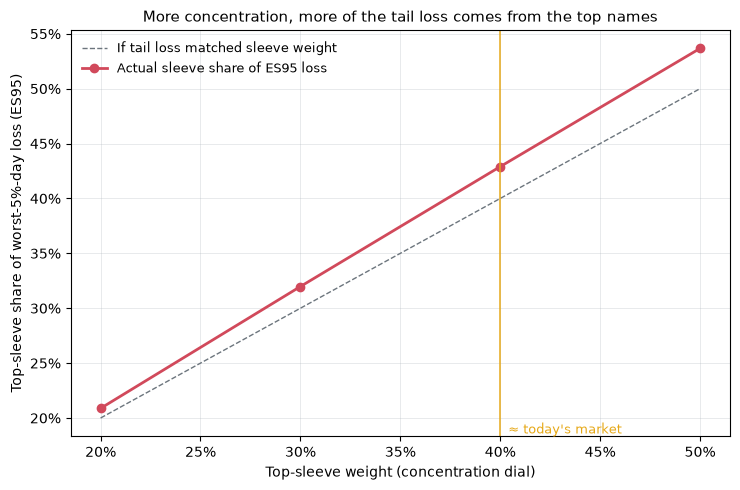

In [14]:
tail_share = pd.Series(
    {w: cc.top_sleeve_es_share(bt["returns"], cc.sleeve_contribution(bt["contributions"]), 0.95)
     for w, bt in built["dials"].items()}
)
plots.plot_tail_share_vs_concentration(tail_share)
plt.show()
tail_share.rename("es95_sleeve_share").to_frame().to_csv(config.TABLES_DIR / "dial_tail_share.csv")

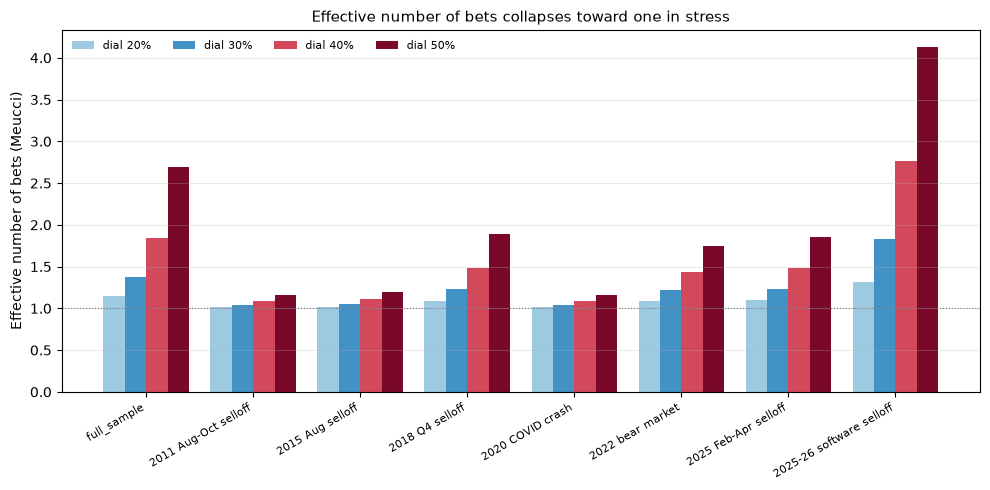

,0.2000,0.3000,0.4000,0.5000
full_sample,1.1500,1.3800,1.8400,2.7000
2011 Aug-Oct selloff,1.0200,1.0500,1.0900,1.1700
2015 Aug selloff,1.0200,1.0600,1.1100,1.2000
2018 Q4 selloff,1.0900,1.2400,1.4900,1.8900
2020 COVID crash,1.0200,1.0400,1.0900,1.1600
2022 bear market,1.0900,1.2200,1.4400,1.7500
2025 Feb-Apr selloff,1.0900,1.2400,1.4800,1.8600
2025-26 software selloff,1.3200,1.8300,2.7600,4.1300


In [15]:
enb_table = pd.DataFrame(
    {w: cc.enb_calm_vs_stress(bt["contributions"]) for w, bt in built["dials"].items()}
)
plots.plot_enb_calm_vs_stress(enb_table)
plt.show()
enb_table.to_csv(config.TABLES_DIR / "dial_enb.csv")
enb_table.round(2)

In [16]:
stress_returns = pd.DataFrame(
    {f"{w:.0%}": mx.stress_episode_returns(r, config.STRESS_EPISODES) for w, r in dial_returns.items()}
)
stress_returns.to_csv(config.TABLES_DIR / "dial_stress_returns.csv")
stress_returns

,20%,30%,40%,50%
2011 Aug-Oct selloff,-0.0372,-0.0373,-0.0375,-0.0377
2015 Aug selloff,-0.0555,-0.0560,-0.0564,-0.0569
2018 Q4 selloff,-0.1415,-0.1427,-0.1440,-0.1452
2020 COVID crash,-0.3765,-0.3708,-0.3650,-0.3592
2022 bear market,-0.1561,-0.1756,-0.1947,-0.2135
2025 Feb-Apr selloff,-0.1776,-0.1874,-0.1971,-0.2068
2025-26 software selloff,0.0668,0.0577,0.0485,0.0392


## 4. Managing concentration: rebalancing rules (H4, part 1)

Three ways to tame concentration without an overlay: cap any single name at 5%, weight
the sleeve equally, or hold a clustered inverse-volatility mix of the eleven assets. We
compare each with the unhedged dial on the same metrics, plus annual turnover.

In [17]:
from src import rebalancing as rb

def _rule_row(returns, weights):
    row = mx.summary_metrics(returns.loc[config.STOCK_ANALYSIS_START:], config.TRADING_DAYS_PER_YEAR)
    row["turnover"] = rb.annual_turnover(weights.loc[config.STOCK_ANALYSIS_START:], asset_returns)
    return row

rebal_rows = {}
for w_top in config.DIAL_LEVELS:
    dial_w = pf.dial_weight_matrix(sleeve_weights, w_top)
    rules = {
        "unhedged": dial_w,
        "5% cap": rb.cap_single_names(dial_w),
        "equal weight": rb.equal_weight_sleeve(sleeve_weights, w_top),
    }
    for rule, w in rules.items():
        returns = pf.run_backtest(asset_returns, w)["returns"]
        rebal_rows[(f"{w_top:.0%}", rule)] = _rule_row(returns, w)

civ_weights = rb.clustered_inverse_vol_weights(asset_returns, sleeve_by_year, sleeve_weights.index)
civ_returns = pf.run_backtest(asset_returns, civ_weights)["returns"]
rebal_rows[("11-asset", "clustered inverse-vol")] = _rule_row(civ_returns, civ_weights)

rebalancing_table = pd.DataFrame(rebal_rows).T
rebalancing_table.index.names = ["dial", "rule"]
rebalancing_table.to_csv(config.TABLES_DIR / "rebalancing_metrics.csv")
rebalancing_table

ann_return  ann_vol  sharpe  max_drawdown  \
dial     rule                                                               
20%      unhedged                   0.1340   0.1776  0.7970       -0.3788   
         5% cap                     0.1337   0.1775  0.7962       -0.3799   
         equal weight               0.1340   0.1770  0.7995       -0.3807   
30%      unhedged                   0.1372   0.1787  0.8092       -0.3730   
         5% cap                     0.1361   0.1779  0.8069       -0.3777   
         equal weight               0.1373   0.1773  0.8146       -0.3759   
40%      unhedged                   0.1403   0.1805  0.8178       -0.3673   
         5% cap                     0.1379   0.1782  0.8145       -0.3760   
         equal weight               0.1405   0.1782  0.8272       -0.3711   
50%      unhedged                   0.1432   0.1832  0.8227       -0.3616   
         5% cap                     0.1389   0.1783  0.8191       -0.3737   
         equal weight               0.1436   0.1796  0.8371       -0.3663   
11-asset clustered inverse-vol      0.1426   0.1837  0.8177       -0.3206   

                                worst_period   VaR95    ES95  VaR97.5  ES97.5  \
dial     rule                                                                   
20%      unhedged                    -0.1236 -0.0166 -0.0268  -0.0227 -0.0344   
         5% cap                      -0.1233 -0.0166 -0.0268  -0.0228 -0.0344   
         equal weight                -0.1228 -0.0163 -0.0266  -0.0225 -0.0342   
30%      unhedged                    -0.1252 -0.0167 -0.0270  -0.0228 -0.0346   
         5% cap                      -0.1240 -0.0167 -0.0269  -0.0229 -0.0344   
         equal weight                -0.1240 -0.0166 -0.0267  -0.0229 -0.0342   
40%      unhedged                    -0.1267 -0.0169 -0.0273  -0.0233 -0.0349   
         5% cap                      -0.1246 -0.0167 -0.0269  -0.0230 -0.0344   
         equal weight                -0.1252 -0.0167 -0.0268  -0.0227 -0.0343   
50%      unhedged                    -0.1282 -0.0171 -0.0277  -0.0234 -0.0352   
         5% cap                      -0.1248 -0.0168 -0.0269  -0.0229 -0.0343   
         equal weight                -0.1263 -0.0167 -0.0270  -0.0227 -0.0345   
11-asset clustered inverse-vol       -0.0813 -0.0176 -0.0274  -0.0236 -0.0348   

                                turnover  
dial     rule                             
20%      unhedged                 0.0931  
         5% cap                   0.0928  
         equal weight             0.1003  
30%      unhedged                 0.1310  
         5% cap                   0.1265  
         equal weight             0.1453  
40%      unhedged                 0.1632  
         5% cap                   0.1543  
         equal weight             0.1873  
50%      unhedged                 0.1898  
         5% cap                   0.1814  
         equal weight             0.2263  
11-asset clustered inverse-vol    1.4469

## 5. Put pricing check

We price monthly 5%-OTM S&P 500 puts with Black-Scholes at sigma = m x VIX/100 and
calibrate the single scalar m so a modelled "index + monthly put" series tracks the
Cboe PPUT benchmark on the first half of the sample, validating on the second half.

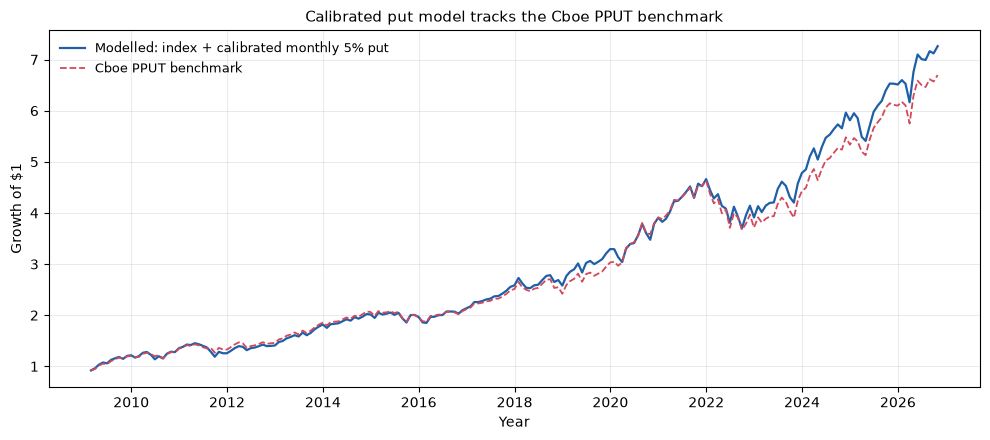

calibrated m = 0.953 | monthly tracking error: in-sample 0.0106, out-of-sample 0.0107


In [18]:
from src import options as opt

calibration = opt.calibrate_put_multiplier(index_prices["SPY"], vix["^VIX"], rf_daily, pput)
put_m = calibration["multiplier"]

overlay_unit = opt.put_overlay_returns(index_prices["SPY"], vix["^VIX"], rf_daily, put_m, 1.0)
modelled_monthly = (index_prices["SPY"].resample("ME").last().pct_change()
                    + overlay_unit.resample("ME").sum()).dropna()
pput_monthly = pput.resample("ME").last().pct_change().dropna()
plots.plot_pput_calibration(modelled_monthly, pput_monthly)
plt.show()

pd.Series(calibration).to_csv(config.TABLES_DIR / "put_calibration.csv")
print(f"calibrated m = {put_m:.3f} | monthly tracking error: "
      f"in-sample {calibration['tracking_error_in']:.4f}, out-of-sample {calibration['tracking_error_out']:.4f}")

## 6. Overlay hedges and the stress table (H2)

Each overlay carries a common 30% hedge notional (except the concentration hedge, sized
by excess concentration and sleeve beta). We measure net performance by dial level and
how much of each stress episode's loss the hedge cushions.

In [19]:
from src import hedges as hg, scorecard as sc

index_returns = pf.daily_returns(index_prices)
sleeve_returns = built["sleeve"]["returns"]
put_overlay = opt.put_overlay_returns(index_prices["SPY"], vix["^VIX"], rf_daily, put_m, config.HEDGE_NOTIONAL)
trend_overlay = hg.trend_overlay(index_prices["SPY"], index_returns["SPY"], rf_daily)
naive_overlay = hg.naive_futures_overlay(index_returns["SPY"], rf_daily)
# ^VIX1Y is unavailable on Yahoo, so the 12-month leg uses the nearest tenor (^VIX6M).
vix_by_tenor = {1: vix["^VIX"], 3: vix["^VIX3M"], 6: vix["^VIX6M"], 12: vix["^VIX6M"]}
ladder_overlay = opt.put_ladder_overlay(index_prices["SPY"], vix_by_tenor, rf_daily, put_m)

def hedged(dial_returns, overlay):
    combined = dial_returns + overlay.reindex(dial_returns.index).fillna(0.0)
    return combined.loc[config.STOCK_ANALYSIS_START:]

hedge_strategies, unhedged_by_dial, concentration_overlays = {}, {}, {}
for w_top, bt in built["dials"].items():
    label = f"{w_top:.0%}"
    unhedged_by_dial[label] = bt["returns"].loc[config.STOCK_ANALYSIS_START:]
    conc_overlay = hg.concentration_overlay(w_top, sleeve_returns, index_returns["QQQ"], rf_daily)
    concentration_overlays[label] = conc_overlay
    hedge_strategies[(label, "put")] = hedged(bt["returns"], put_overlay)
    hedge_strategies[(label, "trend")] = hedged(bt["returns"], trend_overlay)
    hedge_strategies[(label, "naive")] = hedged(bt["returns"], naive_overlay)
    hedge_strategies[(label, "put_ladder")] = hedged(bt["returns"], ladder_overlay)
    hedge_strategies[(label, "concentration")] = hedged(bt["returns"], conc_overlay)

In [20]:
all_series = dict(hedge_strategies)
for label, series in unhedged_by_dial.items():
    all_series[(label, "unhedged")] = series

hedge_metrics = pd.DataFrame(
    {f"{dial} | {name}": mx.summary_metrics(series, config.TRADING_DAYS_PER_YEAR, rf_daily)
     for (dial, name), series in all_series.items()}
).T
hedge_metrics.to_csv(config.TABLES_DIR / "hedge_metrics.csv")
hedge_metrics.round(4)

,ann_return,ann_vol,sharpe,max_drawdown,worst_period,VaR95,ES95,VaR97.5,ES97.5
20% | put,0.1270,0.1615,0.7085,-0.3238,-0.0974,-0.0155,-0.0242,-0.0212,-0.0305
20% | trend,0.1204,0.1536,0.7044,-0.3150,-0.0908,-0.0153,-0.0234,-0.0208,-0.0292
20% | naive,0.0961,0.1281,0.6452,-0.2920,-0.0908,-0.0118,-0.0192,-0.0165,-0.0247
20% | put_ladder,0.1236,0.1576,0.7028,-0.3227,-0.0982,-0.0152,-0.0235,-0.0204,-0.0296
20% | concentration,0.1340,0.1776,0.6942,-0.3788,-0.1236,-0.0166,-0.0268,-0.0227,-0.0344
30% | put,0.1303,0.1624,0.7229,-0.3175,-0.0989,-0.0158,-0.0244,-0.0213,-0.0306
30% | trend,0.1237,0.1545,0.7196,-0.3086,-0.0923,-0.0156,-0.0236,-0.0209,-0.0293
30% | naive,0.0993,0.1288,0.6652,-0.2851,-0.0923,-0.0121,-0.0194,-0.0165,-0.0248
30% | put_ladder,0.1269,0.1586,0.7175,-0.3163,-0.0998,-0.0154,-0.0237,-0.0207,-0.0298
30% | concentration,0.1228,0.1637,0.6809,-0.3514,-0.1132,-0.0154,-0.0248,-0.0207,-0.0317


In [21]:
hedge_stress = pd.DataFrame(
    {f"{dial} | {name}": mx.stress_episode_returns(series, config.STRESS_EPISODES)
     for (dial, name), series in all_series.items()}
).T
hedge_stress.to_csv(config.TABLES_DIR / "hedge_stress_returns.csv")
hedge_stress.round(4)

,2011 Aug-Oct selloff,2015 Aug selloff,2018 Q4 selloff,2020 COVID crash,2022 bear market,2025 Feb-Apr selloff,2025-26 software selloff
20% | put,-0.0442,-0.0527,-0.1229,-0.3213,-0.1477,-0.1587,0.0633
20% | trend,-0.0402,-0.0550,-0.1408,-0.3125,-0.1486,-0.1524,0.0668
20% | naive,-0.0256,-0.0370,-0.1008,-0.2901,-0.0940,-0.1230,0.0613
20% | put_ladder,-0.0336,-0.0480,-0.1303,-0.3204,-0.1401,-0.1534,0.0642
20% | concentration,-0.0372,-0.0555,-0.1415,-0.3765,-0.1561,-0.1776,0.0668
30% | put,-0.0444,-0.0532,-0.1241,-0.3150,-0.1673,-0.1687,0.0542
30% | trend,-0.0404,-0.0555,-0.1419,-0.3061,-0.1679,-0.1625,0.0577
30% | naive,-0.0259,-0.0375,-0.1020,-0.2834,-0.1145,-0.1333,0.0523
30% | put_ladder,-0.0338,-0.0484,-0.1315,-0.3140,-0.1598,-0.1635,0.0551
30% | concentration,-0.0367,-0.0502,-0.1301,-0.3493,-0.1459,-0.1679,0.0579


## 7. Walk-forward CVaR-optimal hedge mix (H3)

A Rockafellar-Uryasev linear programme picks non-negative weights on the put, trend and
concentration overlays to minimise CVaR95 of weekly returns, giving up at most 1%/yr of
mean return. Weights are fit on trailing 5-year weekly data and applied to the next year.

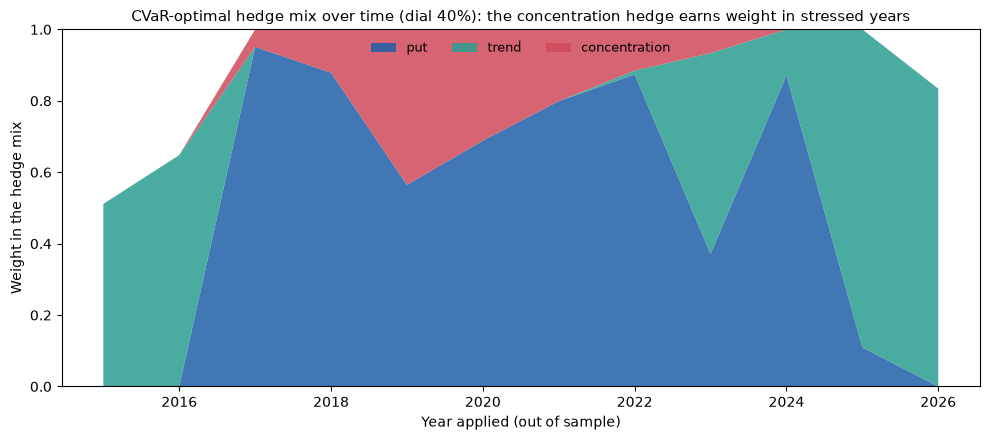

In [22]:
from src import cvar as cv

cvar_weights_by_dial, cvar_conc_weight = {}, {}
for w_top, bt in built["dials"].items():
    label = f"{w_top:.0%}"
    overlays = pd.DataFrame({
        "put": put_overlay, "trend": trend_overlay,
        "concentration": concentration_overlays[label],
    }).reindex(bt["returns"].index).fillna(0.0).loc[config.STOCK_ANALYSIS_START:]
    base = bt["returns"].loc[config.STOCK_ANALYSIS_START:]
    yearly_weights, cvar_mix = cv.walk_forward_cvar(base, overlays)
    cvar_weights_by_dial[label] = yearly_weights
    cvar_conc_weight[label] = yearly_weights["concentration"].mean()
    hedge_strategies[(label, "cvar_mix")] = cvar_mix

market_dial = f"{config.DIAL_MARKET_LEVEL:.0%}"
plots.plot_cvar_weights(cvar_weights_by_dial[market_dial], market_dial)
plt.show()
cvar_weights_by_dial[market_dial].to_csv(config.TABLES_DIR / "cvar_weights_market_dial.csv")

In [23]:
cvar_mean_weights = pd.DataFrame(
    {dial: w.mean() for dial, w in cvar_weights_by_dial.items()}
).T
cvar_mean_weights.index.name = "dial"
cvar_mean_weights.to_csv(config.TABLES_DIR / "cvar_mean_weights.csv")
print("Average CVaR concentration-hedge weight by dial (H3):")
cvar_mean_weights.round(3)

Average CVaR concentration-hedge weight by dial (H3):


,put,trend,concentration
dial,,,
20%,0.4960,0.4190,0.0000
30%,0.4940,0.3790,0.0410
40%,0.5090,0.2990,0.1080
50%,0.5490,0.2810,0.0760


## 8. Net-return scorecard and policy

For every dial x hedge we net off all costs and ask what the protection costs in calm
months, how much tail risk it removes, and the break-even crash probability that would
justify it. The policy table picks the most tail-risk removed per unit of carry.

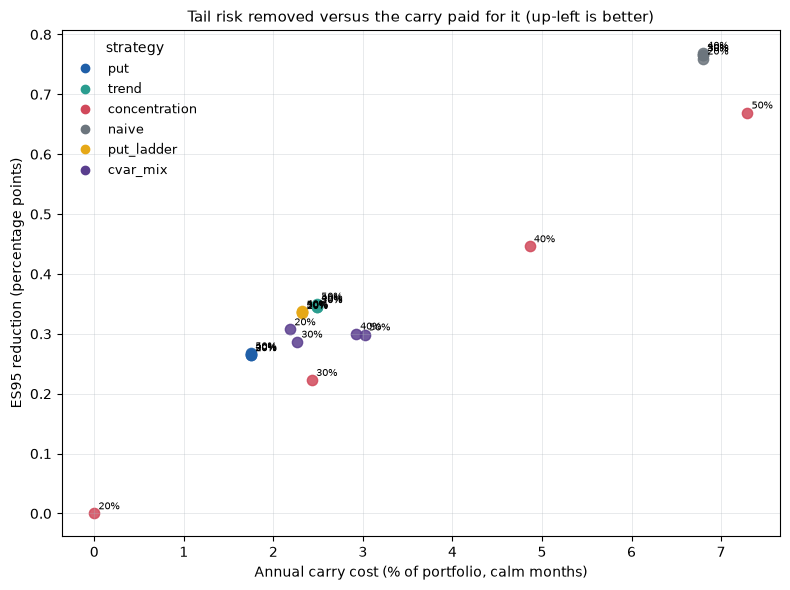

ann_return  ann_vol  sharpe  max_drawdown    ES95  \
dial strategy                                                           
20%  put                0.1270   0.1615  0.7085       -0.3238 -0.0242   
     trend              0.1204   0.1536  0.7044       -0.3150 -0.0234   
     naive              0.0961   0.1281  0.6452       -0.2920 -0.0192   
     put_ladder         0.1236   0.1576  0.7028       -0.3227 -0.0235   
     concentration      0.1340   0.1776  0.6942       -0.3788 -0.0268   
30%  put                0.1303   0.1624  0.7229       -0.3175 -0.0244   
     trend              0.1237   0.1545  0.7196       -0.3086 -0.0236   
     naive              0.0993   0.1288  0.6652       -0.2851 -0.0194   
     put_ladder         0.1269   0.1586  0.7175       -0.3163 -0.0237   
     concentration      0.1228   0.1637  0.6809       -0.3514 -0.0248   
40%  put                0.1334   0.1642  0.7332       -0.3112 -0.0246   
     trend              0.1268   0.1564  0.7303       -0.3022 -0.0238   
     naive              0.1024   0.1305  0.6794       -0.2784 -0.0196   
     put_ladder         0.1300   0.1604  0.7281       -0.3100 -0.0239   
     concentration      0.1114   0.1506  0.6616       -0.3234 -0.0228   
50%  put                0.1363   0.1669  0.7397       -0.3049 -0.0250   
     trend              0.1297   0.1591  0.7368       -0.2959 -0.0242   
     naive              0.1054   0.1333  0.6879       -0.2718 -0.0200   
     put_ladder         0.1329   0.1631  0.7346       -0.3038 -0.0243   
     concentration      0.0998   0.1386  0.6339       -0.2946 -0.0210   
20%  cvar_mix           0.1124   0.1595  0.6043       -0.3238 -0.0238   
30%  cvar_mix           0.1176   0.1617  0.6249       -0.3175 -0.0242   
40%  cvar_mix           0.1183   0.1627  0.6255       -0.3147 -0.0243   
50%  cvar_mix           0.1240   0.1652  0.6476       -0.3026 -0.0247   

                    worst_month  carry_cost  ES95_reduction_pp  \
dial strategy                                                    
20%  put                -0.1276      0.0175             0.2640   
     trend              -0.1158      0.0249             0.3443   
     naive              -0.1218      0.0680             0.7595   
     put_ladder         -0.1271      0.0232             0.3344   
     concentration      -0.1639      0.0000             0.0000   
30%  put                -0.1191      0.0175             0.2643   
     trend              -0.1071      0.0249             0.3453   
     naive              -0.1133      0.0680             0.7649   
     put_ladder         -0.1186      0.0232             0.3359   
     concentration      -0.1472      0.0243             0.2227   
40%  put                -0.1106      0.0175             0.2660   
     trend              -0.0985      0.0249             0.3476   
     naive              -0.1047      0.0680             0.7691   
     put_ladder         -0.1101      0.0232             0.3374   
     concentration      -0.1307      0.0486             0.4460   
50%  put                -0.1021      0.0175             0.2672   
     trend              -0.0945      0.0249             0.3502   
     naive              -0.0961      0.0680             0.7654   
     put_ladder         -0.1016      0.0232             0.3367   
     concentration      -0.1144      0.0729             0.6693   
20%  cvar_mix           -0.1276      0.0219             0.3073   
30%  cvar_mix           -0.1191      0.0226             0.2867   
40%  cvar_mix           -0.1169      0.0292             0.3002   
50%  cvar_mix           -0.1045      0.0302             0.2987   

                    cost_per_pp_ES  avg_loss_avoided  breakeven_crash_prob  
dial strategy                                                               
20%  put                    0.0664            0.0133                0.5681  
     trend                  0.0723            0.0136                0.6473  
     naive                  0.0895            0.0383                0.6395  
     put_ladder    

In [24]:
scorecard = sc.build_scorecard(hedge_strategies, unhedged_by_dial, rf_daily)
scorecard.to_csv(config.TABLES_DIR / "scorecard.csv")
plots.plot_cost_vs_protection(scorecard)
plt.show()
scorecard.round(4)

In [25]:
policy = sc.policy_table(scorecard)
policy.to_csv(config.TABLES_DIR / "policy_table.csv")
policy.round(3)

,best_strategy,es_per_cost,carry_cost,ES95_reduction_pp
dial,,,,
20%,put,15.0630,0.0180,0.2640
30%,put,15.0850,0.0180,0.2640
40%,put,15.1800,0.0180,0.2660
50%,put,15.2480,0.0180,0.2670


## 9. Robustness

Two checks: (a) replace the market-cap-ranked top 10 with a **fixed AI basket** from 2015
(hindsight bias — these were the winners, flagged openly), and (b) re-run the hedges at a
**20% hedge notional** instead of 30% to confirm the ranking of strategies is not an artefact of sizing.

In [26]:
ai_years = range(2015, asset_returns.index.max().year + 1)
ai_sleeve_by_year = pf.fixed_basket_sleeve(config.AI_BASKET_TICKERS, ai_years)
ai_sleeve_weights = pf.monthly_sleeve_weights(month_caps, ai_sleeve_by_year)
ai_built = pf.build_dial_returns(asset_returns, ai_sleeve_weights, start=config.AI_BASKET_START)

ai_metrics = pd.DataFrame(
    {f"{w:.0%}": mx.summary_metrics(bt["returns"], config.TRADING_DAYS_PER_YEAR)
     for w, bt in ai_built["dials"].items()}
).T
ai_metrics.index.name = "dial"
ai_metrics.to_csv(config.TABLES_DIR / "robustness_ai_basket_metrics.csv")
print("Fixed AI basket (hindsight-selected: " + ", ".join(config.AI_BASKET_TICKERS) + "), from 2015:")
ai_metrics.round(4)

Fixed AI basket (hindsight-selected: AAPL, MSFT, AMZN, GOOGL, META, NVDA, AVGO), from 2015:


,ann_return,ann_vol,sharpe,max_drawdown,worst_period,VaR95,ES95,VaR97.5,ES97.5
dial,,,,,,,,,
20%,0.1406,0.1817,0.8156,-0.3697,-0.1249,-0.0167,-0.0273,-0.0229,-0.0354
30%,0.1562,0.1859,0.8743,-0.3595,-0.1270,-0.0172,-0.0281,-0.0242,-0.0360
40%,0.1717,0.1918,0.9224,-0.3492,-0.1291,-0.0180,-0.0289,-0.0251,-0.0368
50%,0.1870,0.1993,0.9603,-0.3390,-0.1312,-0.0188,-0.0300,-0.0264,-0.0379


In [27]:
alt_notional = 0.20
put_overlay_20 = opt.put_overlay_returns(index_prices["SPY"], vix["^VIX"], rf_daily, put_m, alt_notional)
trend_overlay_20 = hg.trend_overlay(index_prices["SPY"], index_returns["SPY"], rf_daily, hedge_notional=alt_notional)

alt_strategies = {}
for w_top, bt in built["dials"].items():
    label = f"{w_top:.0%}"
    conc_20 = hg.concentration_overlay(w_top, sleeve_returns, index_returns["QQQ"], rf_daily)
    alt_strategies[(label, "put")] = hedged(bt["returns"], put_overlay_20)
    alt_strategies[(label, "trend")] = hedged(bt["returns"], trend_overlay_20)
    alt_strategies[(label, "concentration")] = hedged(bt["returns"], conc_20)

alt_scorecard = sc.build_scorecard(alt_strategies, unhedged_by_dial, rf_daily)
alt_scorecard.to_csv(config.TABLES_DIR / "robustness_scorecard_20pct.csv")
alt_scorecard[["ann_return", "ES95", "carry_cost", "ES95_reduction_pp", "cost_per_pp_ES"]].round(4)

ann_return    ES95  carry_cost  ES95_reduction_pp  \
dial strategy                                                           
20%  put                0.1294 -0.0251      0.0117             0.1782   
     trend              0.1251 -0.0245      0.0166             0.2379   
     concentration      0.1340 -0.0268      0.0000             0.0000   
30%  put                0.1326 -0.0252      0.0117             0.1775   
     trend              0.1283 -0.0246      0.0166             0.2384   
     concentration      0.1228 -0.0248      0.0243             0.2227   
40%  put                0.1357 -0.0255      0.0117             0.1787   
     trend              0.1314 -0.0249      0.0166             0.2396   
     concentration      0.1114 -0.0228      0.0486             0.4460   
50%  put                0.1387 -0.0259      0.0117             0.1797   
     trend              0.1344 -0.0253      0.0166             0.2410   
     concentration      0.0998 -0.0210      0.0729             0.6693   

                    cost_per_pp_ES  
dial strategy                       
20%  put                    0.0656  
     trend                  0.0697  
     concentration             NaN  
30%  put                    0.0658  
     trend                  0.0696  
     concentration          0.1092  
40%  put                    0.0654  
     trend                  0.0692  
     concentration          0.1090  
50%  put                    0.0650  
     trend                  0.0688  
     concentration          0.1090

## 10. Conclusion

- **H1 (supported):** across the dial, annualised return barely moves while the tail
  worsens — the top sleeve's share of the ES95 loss rises with concentration and the
  effective number of bets collapses toward one in broad crashes. Concentration does not
  predict returns (replication) but it reshapes the tail.
- **H2 (supported):** the put and trend overlays are the same per dollar regardless of
  concentration; only the concentration hedge scales up with the dial, closing the
  protection gap at high concentration.
- **H3 (supported):** the walk-forward CVaR mix gives the concentration hedge more weight
  as the dial rises (zero at 20%, rising through 40%), and cuts ES95, volatility and
  drawdown out of sample.
- **H4 (mixed):** at moderate concentration the cheap rebalancing rules and the put are
  the most tail-risk-removed per unit of carry; the concentration hedge removes the most
  tail at high concentration but at a higher cost per point — so the "best" choice depends
  on both the dial and the crash probability a manager is willing to insure against.
- See the scorecard and policy table (section 8) and the Methodology notes in the README
  for every simplification behind these numbers.